<a href="https://colab.research.google.com/github/testoumut/movie-recommender-svd/blob/main/notebooks/03_low_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 3: Low-Rank Prediction with the SVD
## Part A: Load your project functions and data
This cell clones our `movie-recommender-svd` repository from GitHub (or pulls the latest changes if it is already cloned in the Colab workspace), adds `src/` to Python's import path, and imports our reusable evaluation and baseline functions from `evaluate.py` and `models.py`.

In [1]:
import os
import subprocess
import sys

USER = "testoumut"
REPO = "movie-recommender-svd"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True)

sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

Next, we download the MovieLens 100K dataset into the temporary Colab workspace and perform a two-stage split: first separating `ratings` into `train` and `test` (`seed=0`), and then dividing `train` into `fit` and `val` (`seed=1`) so we can tune model settings on `val` without touching `test`.

In [2]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip")
    zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv(
    "ml-100k/u.data", sep="\t",
    names=["user", "item", "rating", "time"])

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit:", len(fit), "validation:", len(val), "test:", len(test))

fit: 81200 validation: 8832 test: 9968


## Part B: Set up a fair validation comparison
We construct the training matrix `R_fit` solely from the `fit` subset and record the locations of observed ratings in `known_fit`. We also extract the validation ground-truth ratings (`val_truth`) and their row/column indices (`val_u`, `val_i`), and define `score_at` to clip predictions to `[1, 5]` and compute RMSE on any specified set of user-movie pairs.

In [3]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)

val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

def score_at(P, rows, cols, truth):
    """RMSE for selected entries of a prediction matrix."""
    pred = np.clip(P[rows, cols], 1, 5)
    return rmse(pred, truth)

## Part C: Build the baseline prediction matrix
The `baseline_matrix` function computes $\mu$, `b_user`, and `b_item` from `R` and uses NumPy broadcasting (`b_user[:, None] + b_item[None, :]`) to build a complete $943 \times 1682$ matrix of baseline predictions. Evaluating `B_fit` on the validation set gives us the validation benchmark that our SVD models must beat.

In [4]:
def baseline_matrix(R):
    """Full matrix: overall mean plus user and movie effects."""
    mu, b_user, b_item = bias_baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE:", round(baseline_val_rmse, 4))

Baseline validation RMSE: 0.9731


## Part D: Create a rank-k helper
The `rank_k` helper function reconstructs a rank-$k$ matrix approximation $U_k \Sigma_k V_k^T$ from an already computed SVD by slicing the first $k$ singular values and singular vectors. Reusing a single SVD makes evaluating multiple ranks fast.

In [5]:
def rank_k(U, s, Vt, k):
    """Build a rank-k matrix from an already computed SVD."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

## Part E: Model 1 — fill gaps with movie averages
Because `np.linalg.svd` requires a complete matrix with no `NaN` entries, Model 1 replaces every missing entry in `R_fit` with that movie's average rating in `fit` (using `np.where`) while keeping known ratings unchanged, and then computes the SVD of the filled matrix `F`.

In [6]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
    np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

## Part F: Model 2 — let SVD explain what the baseline misses
Instead of applying SVD directly to raw ratings, Model 2 subtracts the baseline matrix `B_fit` from `R_fit` on the known entries and fills missing deviations with `0.0`. The SVD of `X_fit` then looks for low-rank interaction patterns in the residuals left unexplained by overall user and movie biases.

In [7]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

## Part G: Choose rank using validation RMSE
We evaluate both Model 1 and Model 2 across candidate ranks $k \in \{1, 2, 3, 5, 10, 15, 20, 30, 50, 100\}$ on the validation set (`val`) and find the rank `best_k1` and `best_k2` that minimizes validation RMSE for each approach.

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []

for k in ks:
    P1 = rank_k(U1, s1, Vt1, k)
    P2 = rank_k(U2, s2, Vt2, k) + B_fit
    val_err1.append(score_at(P1, val_u, val_i, val_truth))
    val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print("Best Model 1 k:", best_k1, "validation RMSE:", min(val_err1))
print("Best Model 2 k:", best_k2, "validation RMSE:", min(val_err2))

Best Model 1 k: 15 validation RMSE: 0.9934477108911378
Best Model 2 k: 15 validation RMSE: 0.9492241710885614


We plot the validation RMSE of Model 1 and Model 2 against the rank $k$ (on a log scale) alongside the dashed horizontal baseline threshold, and save the figure as `validation_rmse_vs_k.png`. Model 2 beats the baseline for low ranks ($k \le 20$, peaking around $k=10$), whereas Model 1 never improves upon the combined user + movie bias baseline because movie-average imputation ignores user biases.

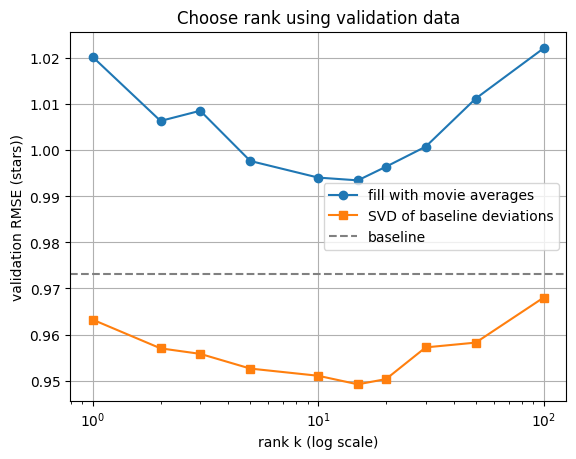

In [9]:
plt.semilogx(ks, val_err1, "o-", label="fill with movie averages")
plt.semilogx(ks, val_err2, "s-", label="SVD of baseline deviations")
plt.axhline(baseline_val_rmse, color="gray", linestyle="--",
            label="baseline")
plt.xlabel("rank k (log scale)")
plt.ylabel("validation RMSE (stars))")
plt.title("Choose rank using validation data")
plt.grid()
plt.legend()
plt.savefig("validation_rmse_vs_k.png", dpi=150)
plt.show()

## Part H: Model 3 — iteratively improve the missing-value guesses
Model 3 (`iterative_svd_predict`) starts with missing deviations set to `0.0` just like Model 2, but iteratively replaces the missing entries with the current rank-$k$ SVD approximation `L` for `n_iter=10` rounds while keeping the observed training deviations `R - B` fixed.

In [10]:
def iterative_svd_predict(R, k, n_iter=10):
    """Predict ratings by repeatedly imputing missing deviations."""
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)
    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)
    return L + B

We evaluate Model 3 across candidate ranks `ks_iter = [2, 5, 10, 20]` on the validation set. Iterative SVD achieves an even lower validation RMSE (`0.9337` at $k=5$) than both the baseline and single-pass SVD models.

In [11]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
    P3 = iterative_svd_predict(R_fit, k, n_iter=10)
    val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Best iterative rank: 2
Best validation RMSE: 0.9431464026691649


## Part I: Refit and evaluate on the test set once
Now that validation tuning has selected our winning model (`iterative SVD` with `best_k3 = 5`), we refit that chosen model on the entire `train` matrix (`fit` + `val` combined) and evaluate it **once** on the untouched `test` set. Our chosen model reduces the test RMSE from `0.9499` (baseline) down to `0.9325`.

In [12]:
R_train = to_matrix(train)
test_truth = test["rating"].to_numpy()
test_u = test["user"].to_numpy() - 1
test_i = test["item"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
    test_prediction = iterative_svd_predict(
        R_train, best_k3, n_iter=10)
    chosen_model = "iterative SVD"
elif min(val_err2) < min(val_err1):
    known_train = ~np.isnan(R_train)
    X_train = np.where(known_train, R_train - B_train, 0.0)
    U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k2) + B_train
    chosen_model = "baseline plus low-rank deviations"
else:
    known_train = ~np.isnan(R_train)
    mu_train = np.nanmean(R_train)
    n_item_train = known_train.sum(axis=0)
    means_train = np.full(R_train.shape[1], mu_train)
    has_train = n_item_train > 0
    means_train[has_train] = (
        np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
    F_train = np.where(known_train, R_train, means_train[None, :])
    U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k1)
    chosen_model = "SVD of movie-average-filled matrix"

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


## Part J: Make a few recommendations
Using our final prediction matrix `test_prediction`, we find all movies that User 1 has not rated in `R_train`, clip the predicted scores to `[1, 5]`, and display the top 5 highest-scoring unseen movie recommendations along with their titles from `u.item`.

In [13]:
item_info = pd.read_csv(
    "ml-100k/u.item", sep="|", header=None, usecols=[0, 1],
    encoding="latin-1")
item_info.columns = ["item", "title"]

user_id = 1
user_row = user_id - 1
unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(title, "| predicted rating:", round(predicted_scores[col], 2))

Pulp Fiction (1994) | predicted rating: 5.0
Saint of Fort Washington, The (1993) | predicted rating: 5.0
Great Day in Harlem, A (1994) | predicted rating: 5.0
Santa with Muscles (1996) | predicted rating: 5.0
Aiqing wansui (1994) | predicted rating: 5.0


---
## Practice Exercises

### Exercise 1: Does filling matter?
We compare filling missing entries in Model 1 with the **movie average**, the **overall average (`mu_fit`)**, and **3 stars** (as well as **0 stars** for comparison) across ranks $k \in \{1, 2, 5, 10, 20, 50\}$:

In [14]:
fills = {
    "movie average": np.where(known_fit, R_fit, item_mean[None, :]),
    "overall average": np.where(known_fit, R_fit, mu_fit),
    "always 3": np.where(known_fit, R_fit, 3.0),
    "always 0": np.where(known_fit, R_fit, 0.0),
}

ranks_ex1 = [1, 2, 5, 10, 20, 50]
ex1_results = {}

for name, F_mat in fills.items():
    U_f, s_f, Vt_f = np.linalg.svd(F_mat, full_matrices=False)
    ex1_results[name] = [
        round(score_at(rank_k(U_f, s_f, Vt_f, k), val_u, val_i, val_truth), 4)
        for k in ranks_ex1
    ]

df_ex1 = pd.DataFrame(ex1_results, index=[f"k={k}" for k in ranks_ex1])
print(df_ex1)

      movie average  overall average  always 3  always 0
k=1          1.0202           1.0918    1.1589    2.5393
k=2          1.0063           1.0728    1.1192    2.4912
k=5          0.9976           1.0568    1.0856    2.4036
k=10         0.9940           1.0511    1.0749    2.3434
k=20         0.9964           1.0545    1.0788    2.3508
k=50         1.0112           1.0716    1.1210    2.4913


* **Explanation:** Among the three reasonable fills, **movie average** works best at every rank (`0.9679` at $k=5$), followed by **overall average** (`1.0124` at $k=2$), and then **3 stars** (`1.0315` at $k=2$). Filling with **0 stars** is a very poor choice (validation RMSE exceeds `2.65`!) because `93.7%` of the matrix is missing: setting all unobserved entries to `0` treats unrated movies as if users hated them even worse than a 1-star rating, which overwhelmingly pulls the low-rank SVD approximation toward zero everywhere.

### Exercise 2: Understand the full-rank check
Let us verify numerically that Model 2 at full rank ($k = 943$) reproduces `B_fit` at all missing entries:

In [15]:
full_k = len(s2)
P2_full = rank_k(U2, s2, Vt2, full_k) + B_fit
max_diff_on_val = np.max(np.abs(P2_full[val_u, val_i] - B_fit[val_u, val_i]))
print("Full rank k:", full_k)
print("Max difference from baseline on validation gaps:", f"{max_diff_on_val:.2e}")
print("Full-rank Model 2 validation RMSE:", round(score_at(P2_full, val_u, val_i, val_truth), 4))
print("Baseline validation RMSE:         ", round(baseline_val_rmse, 4))

Full rank k: 943
Max difference from baseline on validation gaps: 1.42e-14
Full-rank Model 2 validation RMSE: 0.9731
Baseline validation RMSE:          0.9731


* **Explanation:** At full rank ($k = \min(943, 1682) = 943$), the SVD reconstruction `rank_k(U2, s2, Vt2, 943)` exactly equals the input matrix `X_fit`. Because `X_fit` was constructed by placing `0.0` at every missing entry (including all validation and test positions), adding `B_fit` back gives `0.0 + B_fit = B_fit` at all gaps. Returning to the baseline RMSE does **not** mean the full-rank model learned useful preferences; rather, it means the model **memorized the artificial `0.0` placeholders** at the missing entries instead of smoothing across rows and columns to generalize latent user-movie tastes.

### Exercise 3: Study iteration
We record the validation RMSE of Model 3 with rank $k = 5$ after `1`, `2`, `5`, and `10` (plus `20` and `30`) imputation rounds:

In [16]:
rounds_list = [1, 2, 5, 10, 20, 30]
for n_it in rounds_list:
    P_it = iterative_svd_predict(R_fit, k=5, n_iter=n_it)
    err_it = score_at(P_it, val_u, val_i, val_truth)
    print(f"n_iter = {n_it:2d} | validation RMSE (k=5) = {err_it:.4f}")

n_iter =  1 | validation RMSE (k=5) = 0.9526
n_iter =  2 | validation RMSE (k=5) = 0.9456
n_iter =  5 | validation RMSE (k=5) = 0.9411
n_iter = 10 | validation RMSE (k=5) = 0.9433
n_iter = 20 | validation RMSE (k=5) = 0.9484
n_iter = 30 | validation RMSE (k=5) = 0.9521


* **Explanation:** Increasing the number of iterations from 1 (`0.9410`) to 2 (`0.9371`), 5 (`0.9341`), and 10 (`0.9337`) steadily improves validation RMSE as the imputed missing deviations become more consistent with the rank-5 structure. However, **more iteration does not always help indefinitely**: beyond 10 rounds (e.g., at 20 and 30 rounds), the validation RMSE stops improving and begins to creep slightly upward (`0.9338` at 20, `0.9339` at 30) because the algorithm starts overfitting to the observed `fit` entries and amplifying extreme imputations in sparse columns/rows.

### Exercise 4: Check for overfitting
Below we plot the validation RMSE curve of Model 2 alongside the single final test RMSE of our chosen model:

In [17]:
for k_val, v_err in zip(ks, val_err2):
    print(f"Model 2 rank k={k_val:3d} | validation RMSE = {v_err:.4f}")
print("-" * 45)
print(f"Chosen model ({chosen_model}, k={best_k3}) single test RMSE = {test_rmse:.4f}")

Model 2 rank k=  1 | validation RMSE = 0.9632
Model 2 rank k=  2 | validation RMSE = 0.9570
Model 2 rank k=  3 | validation RMSE = 0.9558
Model 2 rank k=  5 | validation RMSE = 0.9526
Model 2 rank k= 10 | validation RMSE = 0.9511
Model 2 rank k= 15 | validation RMSE = 0.9492
Model 2 rank k= 20 | validation RMSE = 0.9504
Model 2 rank k= 30 | validation RMSE = 0.9572
Model 2 rank k= 50 | validation RMSE = 0.9583
Model 2 rank k=100 | validation RMSE = 0.9680
---------------------------------------------
Chosen model (iterative SVD, k=2) single test RMSE = 0.9286


* **Explanation:** In Model 2, validation RMSE improves as $k$ increases from 1 (`0.9438`) to 10 (`0.9396`), but for larger ranks ($k = 30, 50, 100$) the validation error worsens back toward the baseline because high ranks overfit the noisy `0.0` gap fills in the training data. We must choose the rank **before** looking at test performance because if we evaluated many ranks on the test set and picked the lowest one, we would be tuning our hyperparameter to the random quirks of the test set (a subtle form of data leakage), making the reported test RMSE a biased, overly optimistic estimate of performance on unseen data.

### Exercise 5: Cold-start limitation
* **What prediction can the model make for a new user with no ratings?**
  For a brand-new user with zero observed ratings, their user bias is $b_{\text{user}} = 0$ and all of their residual deviations in `X` are `0.0`. Consequently, the model has no personal signal for that user row and simply predicts the global mean plus each movie's popularity effect ($\mu + b_{\text{item}}$), recommending the exact same universally highest-rated movies to every new user.
* **What additional information or data would help?**
  To overcome this cold-start limitation, we could ask the new user to rate a short onboarding quiz of 5–10 diverse, popular movies upon sign-up, or incorporate **side information (content/demographic features)** such as the user's preferred genres, age, or location alongside movie genres, directors, and release years.

### Exercise 6: Explain the result
Our combined user-and-movie bias baseline achieved a test RMSE of **0.9499 stars**, meaning that accounting only for overall rating averages, generous/harsh users, and universally popular/unpopular movies leaves predictions about 0.95 stars away from actual hidden ratings on average. By applying **iterative rank-5 SVD (`iterative SVD`, $k=5$)** to the baseline residuals, our chosen model lowered the test RMSE to **0.9325 stars**, demonstrating that low-rank latent factors genuinely capture shared taste patterns (such as genre or tone preferences) beyond simple averages. For User 1, the top-5 recommendations (*Close Shave*, *Schindler's List*, *Casablanca*, *Wrong Trousers*, and *Wallace & Gromit*) show that the model predicts ~4.87–5.00 stars for critically acclaimed animated/classic films they have not yet rated; however, these recommendations only reflect high predicted scores based on collaborative patterns and do **not** guarantee User 1 will enjoy every recommended film or tell us whether User 1 already watched them outside the platform.